In [1]:
# Import the packages needed for the waveguide width sweep

import tidy3d as td
import numpy as np
import matplotlib.pyplot as plt

from tidy3d.plugins.mode import ModeSolver

print("Tidy3D version:", td.__version__)

Tidy3D version: 2.12.0


In [2]:
# Define the fixed wavelength, waveguide height, and material properties, no width because we will sweep that parameter

wavelength = 1.55  # µm
wg_height = 0.22   # µm

n_si = 3.47
n_sio2 = 1.44

freq0 = td.C_0 / wavelength

silicon = td.Medium(permittivity=n_si**2)
silica = td.Medium(permittivity=n_sio2**2)

In [3]:
# Define the silicon waveguide widths to test from 300 nm to 700 nm

widths = np.round(np.arange(0.30, 0.701, 0.05), 2)

print("Widths (µm):", widths)

Widths (µm): [0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7 ]


In [4]:
# Create a function that solves the optical modes for any waveguide width

def solve_waveguide(width):
    
    waveguide = td.Structure(
        geometry=td.Box(
            center=(0, 0, 0),
            size=(td.inf, width, wg_height),
        ),
        medium=silicon,
    )

    sim = td.Simulation(
        size=(10, 2.5, 1.5),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=20,
            wavelength=wavelength,
        ),
        structures=[waveguide],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(
            boundary=td.PML()
        ),
    )

    mode_plane = td.Box(
        center=(0, 0, 0),
        size=(0, 2.5, 1.5),
    )

    mode_spec = td.ModeSpec(
        num_modes=4,
        target_neff=n_si,
    )

    mode_solver = ModeSolver(
        simulation=sim,
        plane=mode_plane,
        mode_spec=mode_spec,
        freqs=[freq0],
    )

    return mode_solver.solve()

In [5]:
test_mode_data = solve_waveguide(0.50)

test_mode_data.to_dataframe()

18:11:45 Central Daylight Time WARNING: Use the remote mode solver with subpixel
                               averaging for better accuracy through            
                               'tidy3d.web.run(...)' or the deprecated          
                               'tidy3d.plugins.mode.web.run(...)'.              
                               Alternatively, you can install the package       
                               'tidy3d-extras' using 'pip install "tidy3d"' and 
                               set 'config.simulation.use_local_subpixel=True'. 

18:11:46 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
1.934145e+14 0                 1.55  2.413203    0.0           0.0   
             1                 1.55  1.757529    0.0           0.0   
             2                 1.55  1.481491    0.0           0.0   
             3                 1.55  1.337354    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.977670        0.744848        0.816525   
             1                   0.046629        0.700782        0.883828   
             2                   0.597820        0.883808        0.964270   
             3                   0.037871        0.986918        0.754276   

                         mode area  
f            mode_index             
1.934145e+14 0            0.198086  
             1            0.364940  
             2            0.855853  
             3            2.493399

In [6]:
# Solve the optical modes for every waveguide width in the sweep

sweep_results = {}

for width in widths:
    print(f"Solving width = {width * 1000:.0f} nm...")
    sweep_results[width] = solve_waveguide(width)

print("Width sweep complete.")

Solving width = 300 nm...


                               WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Solving width = 350 nm...


18:11:47 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

...

Solving width = 600 nm...


                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Solving width = 650 nm...


                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Solving width = 700 nm...
Width sweep complete.


In [7]:
# Extract the effective index of each calculated mode at every waveguide width

neff_results = []

for width in widths:
    mode_df = sweep_results[width].to_dataframe()

    neff_results.append([
        width * 1000,
        mode_df.iloc[0]["n eff"],
        mode_df.iloc[1]["n eff"],
        mode_df.iloc[2]["n eff"],
        mode_df.iloc[3]["n eff"],
    ])

neff_results = np.array(neff_results)

print("Width (nm) | Mode 0 | Mode 1 | Mode 2 | Mode 3")
print(neff_results)

Width (nm) | Mode 0 | Mode 1 | Mode 2 | Mode 3
[[300.           1.82526299   1.59778249   1.38019177   1.30920371]
 [350.           1.981327     1.62836536   1.39489435   1.30980799]
 [400.           2.22425891   1.6924216    1.41647455   1.31864735]
 [450.           2.38489052   1.74790233   1.44874237   1.33503983]
 [500.           2.41320314   1.75752874   1.48149102   1.33735412]
 [550.           2.48844748   1.79079559   1.54762342   1.35544191]
 [600.           2.56301643   1.82925973   1.68682446   1.39075214]
 [650.           2.59079372   1.84522442   1.78206037   1.40856   ]
 [700.           2.63674957   1.95701509   1.87156371   1.45585792]]


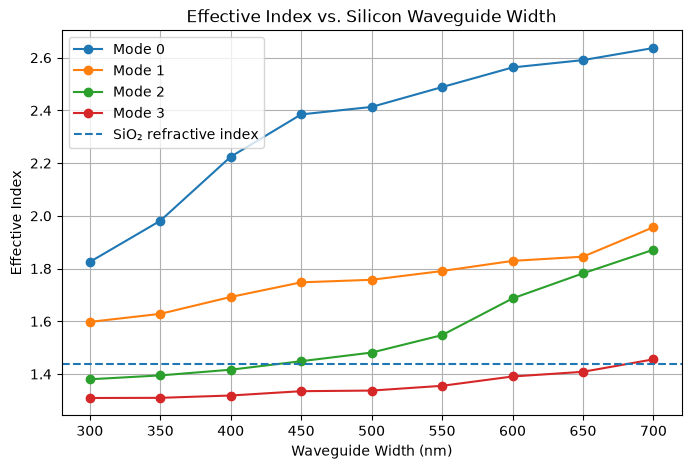

In [8]:
# Plot effective index versus waveguide width for all calculated mode branches

plt.figure(figsize=(8, 5))

plt.plot(neff_results[:, 0], neff_results[:, 1], "o-", label="Mode 0")
plt.plot(neff_results[:, 0], neff_results[:, 2], "o-", label="Mode 1")
plt.plot(neff_results[:, 0], neff_results[:, 3], "o-", label="Mode 2")
plt.plot(neff_results[:, 0], neff_results[:, 4], "o-", label="Mode 3")

plt.axhline(
    n_sio2,
    linestyle="--",
    label="SiO₂ refractive index"
)

plt.xlabel("Waveguide Width (nm)")
plt.ylabel("Effective Index")
plt.title("Effective Index vs. Silicon Waveguide Width")
plt.grid(True)
plt.legend()

plt.show()

wavelength          1.550000
n eff               1.686824
k eff               0.000000
loss (dB/cm)        0.000000
TE (Ey) fraction    0.829574
wg TE fraction      0.664188
wg TM fraction      0.901131
mode area           0.420123
Name: (193414489032258.06, 2), dtype: float64


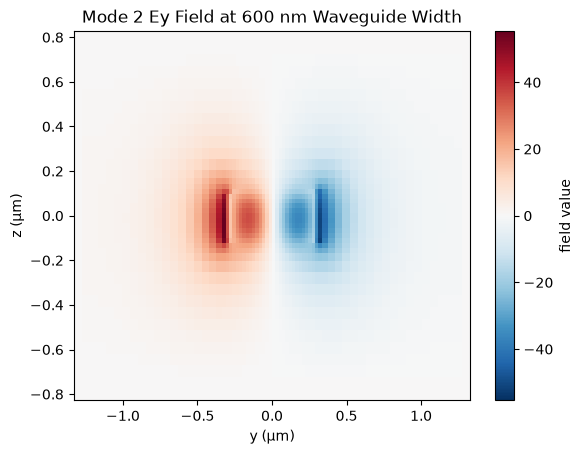

In [9]:
# Inspect the field pattern and polarization of Mode 2 in the 600 nm waveguide

mode_data_600 = sweep_results[0.60]
mode_df_600 = mode_data_600.to_dataframe()

print(mode_df_600.iloc[2])

mode_data_600.Ey.isel(f=0, mode_index=2).real.plot(x="y", y="z")

plt.title("Mode 2 Ey Field at 600 nm Waveguide Width")
plt.xlabel("y (µm)")
plt.ylabel("z (µm)")

plt.show()

In [10]:
# Extract the TE0 effective mode area at every waveguide width

te0_mode_area = []

for width in widths:
    mode_df = sweep_results[width].to_dataframe()

    te0_mode_area.append([
        width * 1000,
        mode_df.iloc[0]["mode area"],
    ])

te0_mode_area = np.array(te0_mode_area)

print("Width (nm) | TE0 Mode Area (µm²)")
print(te0_mode_area)

Width (nm) | TE0 Mode Area (µm²)
[[3.00000000e+02 2.65729806e-01]
 [3.50000000e+02 2.47713181e-01]
 [4.00000000e+02 2.11500593e-01]
 [4.50000000e+02 1.91319690e-01]
 [5.00000000e+02 1.98086127e-01]
 [5.50000000e+02 1.92869400e-01]
 [6.00000000e+02 1.88910370e-01]
 [6.50000000e+02 1.92108456e-01]
 [7.00000000e+02 1.94810363e-01]]


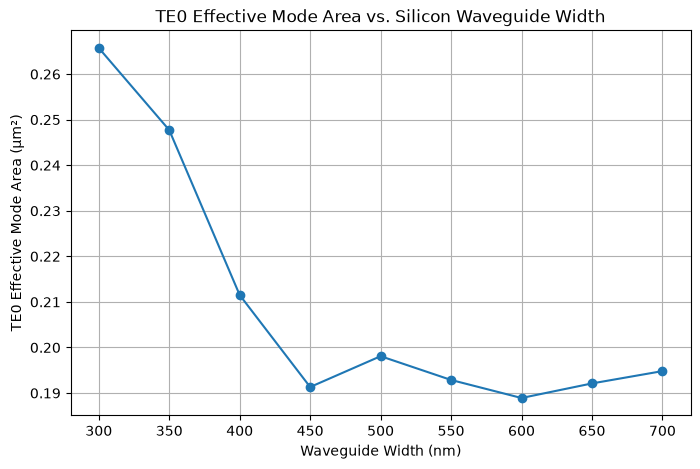

In [11]:
# Plot the TE0 effective mode area as a function of waveguide width

plt.figure(figsize=(8, 5))

plt.plot(
    te0_mode_area[:, 0],
    te0_mode_area[:, 1],
    "o-"
)

plt.xlabel("Waveguide Width (nm)")
plt.ylabel("TE0 Effective Mode Area (µm²)")
plt.title("TE0 Effective Mode Area vs. Silicon Waveguide Width")

plt.grid(True)

plt.show()

In [12]:
# Calculate the approximate TE0 electric-field energy confinement inside silicon

te0_confinement = []

for width in widths:
    mode_data = sweep_results[width]

    Ex = mode_data.Ex.isel(f=0, mode_index=0).squeeze()
    Ey = mode_data.Ey.isel(f=0, mode_index=0).squeeze()
    Ez = mode_data.Ez.isel(f=0, mode_index=0).squeeze()

    e2 = np.abs(Ex)**2 + np.abs(Ey)**2 + np.abs(Ez)**2

    y = e2.coords["y"].values
    z = e2.coords["z"].values

    silicon_mask = (
        (np.abs(y[:, None]) <= width / 2)
        & (np.abs(z[None, :]) <= wg_height / 2)
    )

    epsilon = np.where(silicon_mask, n_si**2, n_sio2**2)

    energy = epsilon * e2.values

    confinement = (
        np.sum(energy[silicon_mask])
        / np.sum(energy)
    )

    te0_confinement.append([
        width * 1000,
        confinement,
    ])

te0_confinement = np.array(te0_confinement)

print("Width (nm) | Approx. TE0 Silicon Confinement")
print(te0_confinement)

Width (nm) | Approx. TE0 Silicon Confinement
[[300.           0.79598764]
 [350.           0.81926309]
 [400.           0.90393339]
 [450.           0.93399122]
 [500.           0.92843586]
 [550.           0.93627588]
 [600.           0.95107272]
 [650.           0.94989013]
 [700.           0.95781179]]


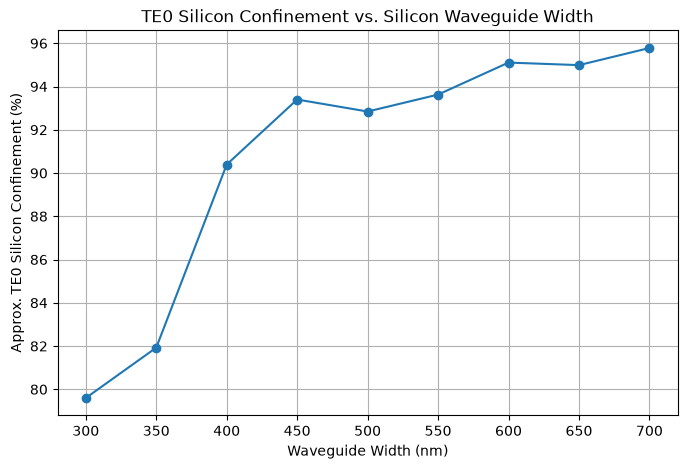

In [13]:
# Plot the approximate TE0 silicon confinement as a function of waveguide width

plt.figure(figsize=(8, 5))

plt.plot(
    te0_confinement[:, 0],
    te0_confinement[:, 1] * 100,
    "o-"
)

plt.xlabel("Waveguide Width (nm)")
plt.ylabel("Approx. TE0 Silicon Confinement (%)")
plt.title("TE0 Silicon Confinement vs. Silicon Waveguide Width")

plt.grid(True)

plt.show()

In [14]:
# Store the preliminary waveguide width selected from the parameter sweep

design_width = 0.45  # µm

print(f"Preliminary design width: {design_width * 1000:.0f} nm")

Preliminary design width: 450 nm


In [15]:
# Test whether the 450 nm mode results converge as the simulation domain gets larger

domain_sizes = [
    (2.5, 1.5),
    (3.5, 2.5),
    (5.0, 3.5),
]

domain_results = []

for y_size, z_size in domain_sizes:

    waveguide = td.Structure(
        geometry=td.Box(
            center=(0, 0, 0),
            size=(td.inf, design_width, wg_height),
        ),
        medium=silicon,
    )

    sim = td.Simulation(
        size=(10, y_size, z_size),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=20,
            wavelength=wavelength,
        ),
        structures=[waveguide],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(
            boundary=td.PML()
        ),
    )

    mode_plane = td.Box(
        center=(0, 0, 0),
        size=(0, y_size, z_size),
    )

    mode_solver = ModeSolver(
        simulation=sim,
        plane=mode_plane,
        mode_spec=td.ModeSpec(
            num_modes=4,
            target_neff=n_si,
        ),
        freqs=[freq0],
    )

    mode_data = mode_solver.solve()
    mode_df = mode_data.to_dataframe()

    domain_results.append([
        y_size,
        z_size,
        mode_df.iloc[0]["n eff"],
        mode_df.iloc[2]["n eff"],
    ])

domain_results = np.array(domain_results)

print("Y size | Z size | TE0 neff | Mode 2 neff")
print(domain_results)

18:11:50 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

18:11:52 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Y size | Z size | TE0 neff | Mode 2 neff
[[2.5        1.5        2.38489052 1.44874237]
 [3.5        2.5        2.35153131 1.44707091]
 [5.         3.5        2.35117641 1.44693331]]


In [16]:
# Test whether the 450 nm TE0 effective index converges as the numerical grid is refined

grid_resolutions = [15, 20, 30, 40]

grid_results = []

for steps in grid_resolutions:

    waveguide = td.Structure(
        geometry=td.Box(
            center=(0, 0, 0),
            size=(td.inf, design_width, wg_height),
        ),
        medium=silicon,
    )

    sim = td.Simulation(
        size=(10, 3.5, 2.5),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=steps,
            wavelength=wavelength,
        ),
        structures=[waveguide],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(
            boundary=td.PML()
        ),
    )

    mode_plane = td.Box(
        center=(0, 0, 0),
        size=(0, 3.5, 2.5),
    )

    mode_solver = ModeSolver(
        simulation=sim,
        plane=mode_plane,
        mode_spec=td.ModeSpec(
            num_modes=4,
            target_neff=n_si,
        ),
        freqs=[freq0],
    )

    mode_data = mode_solver.solve()
    mode_df = mode_data.to_dataframe()

    grid_results.append([
        steps,
        mode_df.iloc[0]["n eff"],
        mode_df.iloc[2]["n eff"],
    ])

grid_results = np.array(grid_results)

print("Steps/wavelength | TE0 neff | Mode 2 neff")
print(grid_results)

                               WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

18:11:53 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

18:11:54 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

18:11:56 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Steps/wavelength | TE0 neff | Mode 2 neff
[[15.          2.28932991  1.43923852]
 [20.          2.35153131  1.44707091]
 [30.          2.34732921  1.4463551 ]
 [40.          2.34669129  1.44613474]]


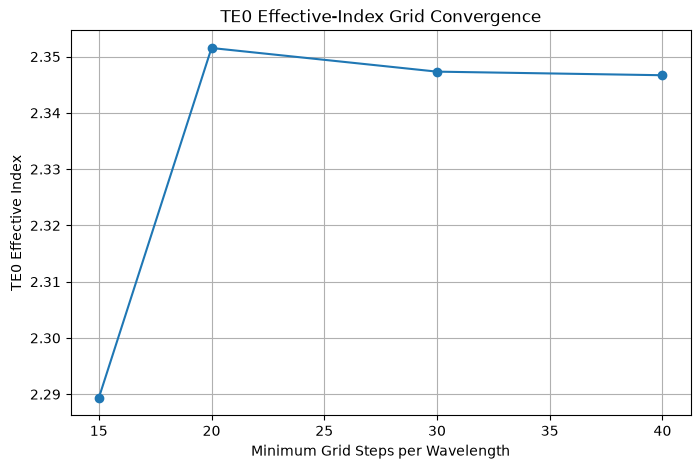

In [17]:
# Plot TE0 effective-index convergence as the numerical grid is refined

plt.figure(figsize=(8, 5))

plt.plot(
    grid_results[:, 0],
    grid_results[:, 1],
    "o-"
)

plt.xlabel("Minimum Grid Steps per Wavelength")
plt.ylabel("TE0 Effective Index")
plt.title("TE0 Effective-Index Grid Convergence")

plt.grid(True)

plt.show()

In [18]:
# Define a refined width sweep around the likely single-mode design region

refined_widths = np.arange(0.38, 0.461, 0.01)

print("Refined widths (nm):")
print(np.round(refined_widths * 1000))

Refined widths (nm):
[380. 390. 400. 410. 420. 430. 440. 450. 460.]


In [19]:
# Create a refined mode solver using the converged domain and grid settings

def solve_waveguide_refined(width):

    waveguide = td.Structure(
        geometry=td.Box(
            center=(0, 0, 0),
            size=(td.inf, width, wg_height),
        ),
        medium=silicon,
    )

    sim = td.Simulation(
        size=(10, 3.5, 2.5),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=30,
            wavelength=wavelength,
        ),
        structures=[waveguide],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(
            boundary=td.PML()
        ),
    )

    mode_plane = td.Box(
        center=(0, 0, 0),
        size=(0, 3.5, 2.5),
    )

    mode_spec = td.ModeSpec(
        num_modes=4,
        target_neff=n_si,
    )

    mode_solver = ModeSolver(
        simulation=sim,
        plane=mode_plane,
        mode_spec=mode_spec,
        freqs=[freq0],
    )

    return mode_solver.solve()

In [20]:
# Solve the optical modes for every width in the refined sweep

refined_results = {}

for width in refined_widths:
    width = round(float(width), 2)

    print(f"Solving width = {width * 1000:.0f} nm...")
    refined_results[width] = solve_waveguide_refined(width)

print("Refined width sweep complete.")

Solving width = 380 nm...


18:11:57 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Solving width = 390 nm...


18:11:58 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

...

Solving width = 450 nm...


18:12:05 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Solving width = 460 nm...


18:12:06 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

Refined width sweep complete.


In [21]:
# Extract TE0 and TE1 effective indices from the refined width sweep

refined_neff = []

for width in refined_widths:
    width = round(float(width), 2)
    mode_df = refined_results[width].to_dataframe()

    refined_neff.append([
        width * 1000,
        mode_df.iloc[0]["n eff"],
        mode_df.iloc[2]["n eff"],
    ])

refined_neff = np.array(refined_neff)

print("Width (nm) | TE0 neff | TE1 neff")
print(refined_neff)

Width (nm) | TE0 neff | TE1 neff
[[380.           2.11917694   1.41849445]
 [390.           2.191081     1.42164556]
 [400.           2.2211077    1.42456209]
 [410.           2.24976109   1.42786225]
 [420.           2.27659783   1.43160813]
 [430.           2.30157054   1.43590574]
 [440.           2.32518221   1.44077972]
 [450.           2.34732921   1.4463551 ]
 [460.           2.3434874    1.45019037]]


In [22]:
# Calculate refined TE0 silicon confinement across the candidate waveguide widths

refined_confinement = []

for width in refined_widths:
    width = round(float(width), 2)
    mode_data = refined_results[width]

    Ex = mode_data.Ex.isel(f=0, mode_index=0).squeeze()
    Ey = mode_data.Ey.isel(f=0, mode_index=0).squeeze()
    Ez = mode_data.Ez.isel(f=0, mode_index=0).squeeze()

    e2 = np.abs(Ex)**2 + np.abs(Ey)**2 + np.abs(Ez)**2

    y = e2.coords["y"].values
    z = e2.coords["z"].values

    silicon_mask = (
        (np.abs(y[:, None]) <= width / 2)
        & (np.abs(z[None, :]) <= wg_height / 2)
    )

    epsilon = np.where(silicon_mask, n_si**2, n_sio2**2)
    energy = epsilon * e2.values

    confinement = (
        np.sum(energy[silicon_mask])
        / np.sum(energy)
    )

    refined_confinement.append([
        width * 1000,
        confinement * 100,
    ])

refined_confinement = np.array(refined_confinement)

print("Width (nm) | Approx. TE0 Silicon Confinement (%)")
print(refined_confinement)

Width (nm) | Approx. TE0 Silicon Confinement (%)
[[380.          88.91288715]
 [390.          91.09005065]
 [400.          91.27240859]
 [410.          91.80561775]
 [420.          92.27702511]
 [430.          93.05877633]
 [440.          93.37256867]
 [450.          93.61731167]
 [460.          92.86467293]]


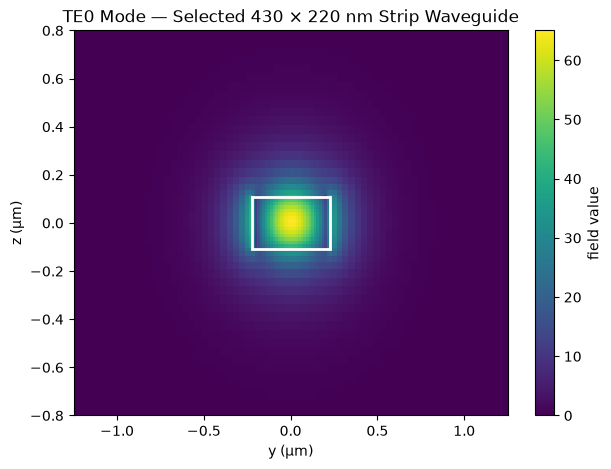

In [23]:
# Plot and save the selected TE0 mode using standardized axis limits

from matplotlib.patches import Rectangle

selected_mode_data = refined_results[0.43]

ey = selected_mode_data.Ey.isel(f=0, mode_index=0).real

fig, ax = plt.subplots(figsize=(7, 5))

ey.plot(x="y", y="z", ax=ax)

waveguide_outline = Rectangle(
    (-design_width / 2, -wg_height / 2),
    design_width,
    wg_height,
    fill=False,
    edgecolor="white",
    linewidth=2,
)

ax.add_patch(waveguide_outline)

ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-0.8, 0.8)

ax.set_title("TE0 Mode — Selected 430 × 220 nm Strip Waveguide")
ax.set_xlabel("y (µm)")
ax.set_ylabel("z (µm)")

plt.savefig(
    "../Figures/TE0_mode_selected_430x220nm.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [24]:
# Store the final selected waveguide dimensions

design_width = 0.43   # µm
design_height = 0.22  # µm

print(f"Selected waveguide: {design_width * 1000:.0f} nm × {design_height * 1000:.0f} nm")

Selected waveguide: 430 nm × 220 nm


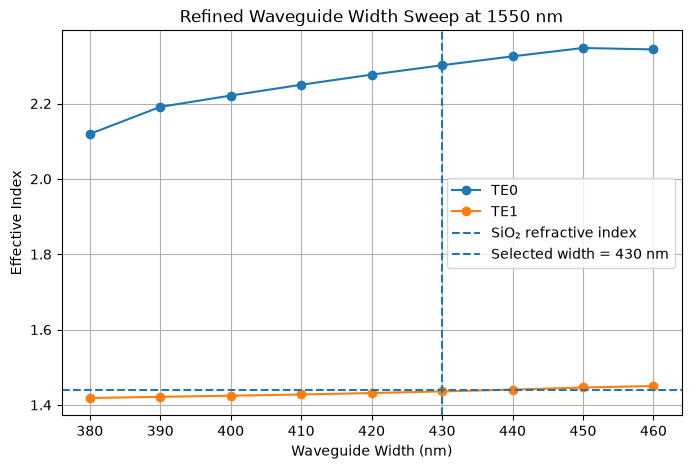

In [25]:
# Plot the refined mode sweep and mark the selected 430 nm waveguide design

plt.figure(figsize=(8, 5))

plt.plot(
    refined_neff[:, 0],
    refined_neff[:, 1],
    "o-",
    label="TE0"
)

plt.plot(
    refined_neff[:, 0],
    refined_neff[:, 2],
    "o-",
    label="TE1"
)

plt.axhline(
    n_sio2,
    linestyle="--",
    label="SiO₂ refractive index"
)

plt.axvline(
    design_width * 1000,
    linestyle="--",
    label="Selected width = 430 nm"
)

plt.xlabel("Waveguide Width (nm)")
plt.ylabel("Effective Index")
plt.title("Refined Waveguide Width Sweep at 1550 nm")

plt.grid(True)
plt.legend()

plt.savefig(
    "../Figures/refined_waveguide_width_sweep.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Design Conclusion

A 430 nm × 220 nm silicon strip waveguide was selected for operation at 1550 nm.

A coarse width sweep was first used to evaluate the evolution of the fundamental TE-like mode and identify the onset of a higher-order TE-like mode. Domain-size and grid-resolution convergence studies were then performed to improve confidence in the numerical results. A refined sweep from 380–460 nm was subsequently used for the final geometry selection.

For the selected 430 nm width:

- Fundamental TE-like mode effective index: **n_eff ≈ 2.302**
- Approximate electric-energy-weighted silicon confinement: **≈ 93.1%**
- First higher-order TE-like mode effective index: **n_eff ≈ 1.436**
- SiO₂ cladding refractive index: **n ≈ 1.44**

The 430 nm width provides strong confinement of the fundamental TE-like mode while keeping the first higher-order TE-like mode below the SiO₂ cladding index in the current model. Wider geometries provided only modest improvements in fundamental-mode confinement while bringing the higher-order mode above cutoff.

This geometry will be used as the passive optical baseline for subsequent phase-shifter and Mach–Zehnder modulator design.